# Notebook 03: competição entre modelos e promoção controlada

Este notebook reúne as etapas 4 e 5 do pipeline:

1. **Competição:** o Modelo A (Random Forest) e o Modelo B (Regressão Logística) são treinados com as mesmas features eleitas, o mesmo treino e a mesma validação cruzada. O melhor pela métrica principal (F1 da classe spam) é o **desafiante**.
2. **Promoção controlada:** o desafiante só substitui o modelo vigente se for melhor que ele por uma margem mínima e atingir um F1 mínimo. Isso evita trocar de modelo por diferenças que são apenas ruído.

| | Arquivos |
|---|---|
| **Lê** | `config/config.yaml`, `artifacts/ciclo_atual.json`, `artifacts/features_eleitas.json`, `data/processed/treino_<data_version>.csv`, `models/modelo_vigente.json` |
| **Grava** | `models/modelo_vigente.json`, `models/historico/<algoritmo>_<hash>.joblib`, `models/historico/indice_modelos.csv`, `reports/figuras/<cycle_id>_03_*.csv` e `.png`, runs no MLflow (um por modelo, um de reavaliação do vigente e um de decisão) |

**Sobre vazamento de dados.** O teste fixo não é usado em nenhuma decisão deste notebook: a escolha do vencedor e a promoção usam apenas a validação cruzada no treino. Cada modelo é um `Pipeline` completo (votação de features, `StandardScaler` quando necessário e o classificador), reajustado do zero em cada fold só com a parte de treino daquele fold.

## 0. Preparação do ambiente

Esta célula faz o mesmo notebook rodar sem alterações no **Google Colab**, no **GitHub Actions** e **localmente**:

* **No Colab** (`'google.colab' in sys.modules`): clona o repositório definido em `REPO_URL` dentro de `/content`, entra na pasta e instala o `requirements.txt`. Se o repositório já estiver clonado, só atualiza com `git pull`. Se a instalação trocar a versão de uma biblioteca que o Colab já tinha carregado, a sessão é reiniciada automaticamente: basta executar esta célula de novo.
* **Fora do Colab**: procura a raiz do repositório (a pasta que contém `config/config.yaml`) subindo a partir da pasta atual e muda o diretório de trabalho para ela.

Nos dois casos a raiz entra no `sys.path`, o que permite `from src... import ...`. Todos os caminhos usados depois são relativos à raiz.

**`REPO_URL` já aponta para o repositório do projeto (`https://github.com/eduardaramalho/n3-analise-preditiva.git`). Só altere se o repositório mudar de endereço.**

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/eduardaramalho/n3-analise-preditiva.git"  # repositório do projeto
REPO_BRANCH = "main"

NA_COLAB = "google.colab" in sys.modules

if NA_COLAB:
    pasta_repo = Path("/content") / Path(REPO_URL).stem
    if not (pasta_repo / ".git").exists():
        subprocess.run(["git", "clone", "-b", REPO_BRANCH, REPO_URL, str(pasta_repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(pasta_repo), "pull", "--ff-only"], check=False)
    os.chdir(pasta_repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # Se o pip trocou a versão de uma biblioteca já carregada, a sessão precisa reiniciar
    from importlib.metadata import version
    trocadas = [m for m, dist in {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
                                  "matplotlib": "matplotlib"}.items()
                if m in sys.modules and getattr(sys.modules[m], "__version__", version(dist)) != version(dist)]
    if trocadas:
        print(f"Versões atualizadas ({', '.join(trocadas)}). Reiniciando a sessão: execute esta célula de novo.")
        os.kill(os.getpid(), 9)
else:
    raiz = Path.cwd().resolve()
    while not (raiz / "config" / "config.yaml").exists():
        if raiz.parent == raiz:
            raise FileNotFoundError("Raiz do repositório não encontrada (config/config.yaml).")
        raiz = raiz.parent
    os.chdir(raiz)

RAIZ = Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
print("Ambiente:", "Google Colab" if NA_COLAB else "local / GitHub Actions")
print("Raiz do repositório:", RAIZ)

Ambiente: local / GitHub Actions
Raiz do repositório: /home/user/n3-analise-preditiva


## 1. Configuração, dados e features do ciclo

Carregamos o treino do ciclo e a lista de features eleitas no notebook 02. O notebook confere se `features_eleitas.json` é do mesmo ciclo e do mesmo `data_version`. Se não for (por exemplo, o 02 não rodou neste ciclo), a execução para.

In [2]:
import mlflow
import pandas as pd
from IPython.display import display

from src.utils import carregar_config, caminho, fixar_seed, ler_json
from src import ingestao, features as F, modelagem as M, promocao as P, graficos
from src.preprocessamento import colunas_features
from src.rastreamento import configurar_mlflow, registrar_modelo_sem_duplicar

cfg = carregar_config()
SEED = cfg["projeto"]["seed"]
fixar_seed(SEED)
graficos.aplicar_estilo()

ciclo = ingestao.carregar_ciclo(cfg)
CYCLE_ID, DATA_VERSION = ciclo["cycle_id"], ciclo["data_version"]
ALVO, COL_ID = cfg["dados"]["alvo"], cfg["dados"]["coluna_id"]

treino = pd.read_csv(caminho(ciclo["arquivo_treino"]))
if not DATA_VERSION.endswith(f"_h{ingestao.hash_treino(treino, COL_ID)}"):
    raise ValueError("O treino não confere com o data_version do ciclo")
eleicao = ler_json(cfg["caminhos"]["features_eleitas"])
if eleicao is None or eleicao["cycle_id"] != CYCLE_ID or eleicao["data_version"] != DATA_VERSION:
    raise ValueError("artifacts/features_eleitas.json não é deste ciclo. Execute o notebook 02 antes.")
ELEITAS = eleicao["features_eleitas"]

FEATURES = colunas_features(treino, cfg)
X, y = treino[FEATURES], treino[ALVO]
METRICA, DIRECAO = cfg["metrica"]["principal"], cfg["metrica"]["direcao"]
METRICAS = [METRICA] + cfg["metrica"]["secundarias"]
print(f"Ciclo {CYCLE_ID} | {DATA_VERSION} | treino {X.shape}")
print(f"{len(ELEITAS)} features eleitas | métrica principal: {METRICA} ({DIRECAO})")

Ciclo 20261122T202252Z | lotes-01+02_h0ce6906487cc | treino (3363, 57)
20 features eleitas | métrica principal: f1 (maximizar)


## 2. Protocolo de avaliação (igual para todos os modelos)

* **Mesmo treino:** o treino do ciclo, identificado pelo `data_version`.
* **Mesma validação cruzada:** `StratifiedKFold` com 5 folds, `shuffle=True` e `random_state=42`. Estratificado significa que cada fold mantém a proporção de spam do treino (cerca de 40%). Como a seed é fixa, **os 5 folds são exatamente os mesmos** para A, B e o vigente: as diferenças entre os modelos vêm dos modelos, não da sorte na divisão.
* **Mesmas features:** os dois modelos começam com o `SeletorPorVotacao` no Pipeline. Em cada fold a votação é refeita só com o treino do fold (sem vazamento). No ajuste final com todo o treino, a votação chega às mesmas features eleitas do notebook 02, o que é conferido na seção 5.
* **Métricas**, todas calculadas para a classe positiva (spam = 1) e resumidas pela média e pelo desvio padrão dos 5 folds:

| Métrica | O que mede | Por que importa aqui |
|---|---|---|
| **F1** (principal) | média harmônica entre precisão e recall | equilibra os dois erros e não é enganada pelo desbalanceamento (60% não spam) |
| **Precisão** | dos e-mails marcados como spam, quantos eram spam | erro aqui = e-mail legítimo indo para o lixo, o mais caro para o usuário |
| **Recall** | dos spams reais, quantos foram pegos | erro aqui = spam chegando na caixa de entrada |
| **Acurácia** | acertos totais | fácil de comunicar, mas um modelo que diz sempre "não spam" já teria 60% |
| **ROC AUC** | capacidade de ordenar spam acima de não spam, em todos os limiares | avalia o modelo independentemente do limiar de 0,5 |

## 3. Os modelos A e B e seus hiperparâmetros

| | Modelo A: `RandomForestClassifier` | Modelo B: `LogisticRegression` |
|---|---|---|
| Ideia | conjunto de árvores de decisão; cada uma vê uma amostra bootstrap dos dados e um subconjunto aleatório de features em cada divisão; o voto da maioria decide | modelo linear que estima a probabilidade de spam com a função logística |
| Hiperparâmetros | `n_estimators=300`: número de árvores (mais árvores = previsões mais estáveis, com custo maior)<br>`max_depth=None`: árvores crescem até as folhas ficarem puras; o conjunto compensa o sobreajuste de cada árvore<br>`min_samples_leaf=1`: folha pode ter um único exemplo<br>`max_features="sqrt"`: em cada divisão sorteia raiz(n) features, o que deixa as árvores diferentes entre si<br>`n_jobs=-1`: usa todos os núcleos | `C=1.0`: inverso da força de regularização (padrão)<br>`penalty="l2"`: regularização ridge, encolhe coeficientes sem zerá-los<br>`solver="lbfgs"`: otimizador padrão, estável em problemas binários<br>`max_iter=5000`: iterações suficientes para convergir |
| Escalonamento | não precisa (árvores dividem por limiares) | `StandardScaler` dentro do Pipeline |
| Por que competem bem | captura não linearidades e interações entre palavras | simples, rápido, interpretável e bem calibrado |

Os dois recebem `random_state=42`.

In [3]:
CANDIDATOS = {}
for chave in ("modelo_a", "modelo_b"):
    spec = cfg["competicao"][chave]
    CANDIDATOS[chave] = {
        "algoritmo": spec["algoritmo"],
        "hiperparametros": spec["hiperparametros"],
        "pipeline": M.construir_pipeline(spec["algoritmo"], spec["hiperparametros"], SEED, seletor=F.criar_seletor(cfg)),
    }
ROTULOS = {k: f"Modelo {k[-1].upper()} ({v['algoritmo']})" for k, v in CANDIDATOS.items()}
for k, v in CANDIDATOS.items():
    print(ROTULOS[k], "->", [nome for nome, _ in v["pipeline"].steps])

Modelo A (RandomForestClassifier) -> ['seletor', 'modelo']
Modelo B (LogisticRegression) -> ['seletor', 'escalonador', 'modelo']


## 4. Validação cruzada dos dois modelos

Para cada fold: o Pipeline inteiro é clonado (sem nada aprendido), ajustado no treino do fold (votação, escalonamento e modelo) e avaliado na validação do fold. A tabela mostra as métricas em cada fold e o resumo (média e desvio).

In [4]:
POR_FOLD, RESUMOS = {}, {}
for chave, cand in CANDIDATOS.items():
    por_fold, _ = M.validar_cruzado(cand["pipeline"], X, y, cfg)
    POR_FOLD[chave], RESUMOS[chave] = por_fold, M.resumir_folds(por_fold)

tabela_folds = pd.concat({ROTULOS[k]: v for k, v in POR_FOLD.items()}, names=["modelo"]).round(4)
graficos.salvar_tabela(tabela_folds, cfg, CYCLE_ID, "03_metricas_por_fold", index=True)
tabela_folds

f1  precision  recall  accuracy  \
modelo                            fold                                        
Modelo A (RandomForestClassifier) 1     0.9262     0.9194  0.9331    0.9406   
                                  2     0.9236     0.9219  0.9254    0.9391   
                                  3     0.9118     0.9170  0.9067    0.9302   
                                  4     0.9381     0.9434  0.9328    0.9509   
                                  5     0.9276     0.9225  0.9328    0.9420   
Modelo B (LogisticRegression)     1     0.8868     0.9004  0.8736    0.9108   
                                  2     0.8889     0.9306  0.8507    0.9153   
                                  3     0.8627     0.9091  0.8209    0.8960   
                                  4     0.8936     0.9277  0.8619    0.9182   
                                  5     0.8963     0.9424  0.8545    0.9211   

                                        roc_auc  
modelo                            fold           
Modelo A (RandomForestClassifier) 1      0.9757  
                                  2      0.9753  
                                  3      0.9774  
                                  4      0.9825  
                                  5      0.9763  
Modelo B (LogisticRegression)     1      0.9603  
                                  2      0.9685  
                                  3      0.9600  
                                  4      0.9744  
                                  5      0.9714

## 5. Ajuste final e conferência das features

Cada Pipeline é ajustado uma última vez com **todo** o treino do ciclo. Esse é o modelo que pode ser promovido. Conferimos que o seletor dentro de cada Pipeline elegeu exatamente as features do `features_eleitas.json`: assim A e B usam as mesmas features, e são as mesmas registradas no notebook 02.

In [5]:
for chave, cand in CANDIDATOS.items():
    cand["pipeline"].fit(X, y)
    eleitas_pipeline = cand["pipeline"].named_steps["seletor"].features_eleitas_
    if eleitas_pipeline != ELEITAS:
        raise ValueError(f"{ROTULOS[chave]}: features diferentes das eleitas no notebook 02")
    cand["hash"] = P.hash_modelo(cand["pipeline"])
    print(f"{ROTULOS[chave]}: {len(eleitas_pipeline)} features, iguais às eleitas | hash {cand['hash']}")

Modelo A (RandomForestClassifier): 20 features, iguais às eleitas | hash a927bb7b32c0dc77


Modelo B (LogisticRegression): 20 features, iguais às eleitas | hash 4d0f75d3a97a00f8


## 6. Registro no MLflow e no histórico: um run por modelo

Cada run guarda os hiperparâmetros, a seed, a configuração da validação, as métricas (média e desvio, além do valor de cada fold como `step`), as features, o `cycle_id`, o `data_version` e o **pipeline completo serializado** (seletor, escalonador e classificador juntos, prontos para prever a partir das 57 colunas brutas).

**Sem cópias repetidas.** Uma Random Forest de 300 árvores ocupa cerca de 12 MB. Como o repositório é commitado a cada ciclo, guardar o mesmo modelo todo dia incharia o Git. Cada pipeline treinado recebe um hash (impressão digital). Se um run anterior já guardou um modelo com o mesmo hash (mesmo treino, mesma configuração e mesma seed, o que acontece nos ciclos sem dados novos), o run atual só aponta para ele pela tag `modelo_uri`. O mesmo vale para `models/historico/`: cada modelo distinto vira um arquivo `<algoritmo>_<hash>.joblib` comprimido, que nunca é sobrescrito, e o índice `indice_modelos.csv` ganha uma linha por modelo por ciclo.

In [6]:
configurar_mlflow(cfg)
X_exemplo = X.head(3)
linhas_indice = []
for chave, cand in CANDIDATOS.items():
    with mlflow.start_run(run_name=f"{chave}_{cand['algoritmo']}_{CYCLE_ID}") as run:
        mlflow.set_tags({"etapa": "competicao", "modelo": chave, "algoritmo": cand["algoritmo"],
                         "cycle_id": CYCLE_ID, "data_version": DATA_VERSION})
        mlflow.log_params({"algoritmo": cand["algoritmo"], "seed": SEED, "cycle_id": CYCLE_ID,
                           "data_version": DATA_VERSION, "cv_estrategia": cfg["validacao"]["estrategia"],
                           "cv_n_splits": cfg["validacao"]["n_splits"], "n_features": len(ELEITAS),
                           "n_linhas_treino": len(X),
                           **{f"hp__{k}": v for k, v in cand["hiperparametros"].items()}})
        mlflow.log_metrics(RESUMOS[chave])
        for fold, linha in POR_FOLD[chave].iterrows():
            mlflow.log_metrics({f"fold_{m}": float(v) for m, v in linha.items()}, step=int(fold))
        mlflow.log_dict({"features_eleitas": ELEITAS}, "features.json")
        mlflow.log_text(str(cand["pipeline"]), "pipeline.txt")
        reg = registrar_modelo_sem_duplicar(cand["pipeline"], cand["hash"], X_exemplo, cfg)
        cand["run_id"], cand["modelo_uri"] = run.info.run_id, reg["modelo_uri"]

    cand["arquivo_modelo"], criado = P.salvar_no_historico(cand["pipeline"], cfg, cand["algoritmo"], cand["hash"])
    linhas_indice.append({"cycle_id": CYCLE_ID, "data_version": DATA_VERSION, "modelo": chave,
                          "algoritmo": cand["algoritmo"], "run_id": cand["run_id"], "hash": cand["hash"],
                          "arquivo": cand["arquivo_modelo"], "arquivo_novo": criado,
                          "modelo_uri": cand["modelo_uri"], f"{METRICA}_media": RESUMOS[chave][f"{METRICA}_media"]})
    print(f"{ROTULOS[chave]}: run {cand['run_id']} | modelo MLflow {'reaproveitado de ' + reg['reaproveitado_de'] if reg['reaproveitado_de'] else 'salvo'}"
          f" | histórico {'novo arquivo' if criado else 'arquivo já existente'}")
indice = P.registrar_indice(cfg, linhas_indice)

2026/11/22 20:23:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/22 20:23:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo A (RandomForestClassifier): run 1403b0938a334226aeb61933bde1152b | modelo MLflow salvo | histórico novo arquivo
Modelo B (LogisticRegression): run cc181bd196584f2c94e00a2f38e20aec | modelo MLflow salvo | histórico novo arquivo


## 7. Eleição automática do vencedor

Vence quem tiver a **maior média de F1** nos 5 folds (`direcao: maximizar`). Em caso de empate na sexta casa decimal, vence o de menor desvio padrão (o mais estável); persistindo, o Modelo A.

In [7]:
VENCEDOR = P.eleger_vencedor(RESUMOS, METRICA, DIRECAO)
comparacao = pd.DataFrame(RESUMOS).T
comparacao.index = [ROTULOS[k] for k in comparacao.index]
graficos.salvar_tabela(comparacao.round(4), cfg, CYCLE_ID, "03_comparacao_a_x_b", index=True)
print(f"Vencedor (desafiante): {ROTULOS[VENCEDOR]} com F1 = {RESUMOS[VENCEDOR][METRICA + '_media']:.4f}")
comparacao[[f"{m}_{s}" for m in METRICAS for s in ("media", "desvio")]].round(4)

Vencedor (desafiante): Modelo A (RandomForestClassifier) com F1 = 0.9255


,f1_media,f1_desvio,precision_media,precision_desvio,recall_media,recall_desvio,accuracy_media,accuracy_desvio,roc_auc_media,roc_auc_desvio
Modelo A (RandomForestClassifier),0.9255,0.0094,0.9248,0.0106,0.9262,0.0114,0.9405,0.0074,0.9775,0.0030
Modelo B (LogisticRegression),0.8857,0.0134,0.9220,0.0170,0.8523,0.0196,0.9123,0.0099,0.9669,0.0065


## 8. Reavaliação do modelo vigente pelo mesmo protocolo

Não faz sentido comparar o F1 que o vigente teve no ciclo em que foi treinado com o F1 do desafiante agora: os dados são outros. Por isso a **configuração do vigente** (algoritmo, hiperparâmetros e a lista de features dele, lidos de `models/modelo_vigente.json`) é treinada e avaliada de novo nos **mesmos 5 folds do treino atual**.

Diferença assumida: o vigente usa a sua lista fixa de features, enquanto os desafiantes refazem a votação dentro de cada fold. A lista do vigente foi escolhida em ciclos anteriores, com dados que estão contidos no treino atual, o que poderia favorecê-lo um pouco (viés conservador: dificulta a promoção, nunca facilita). Na prática, a diferença entre usar a lista fixa e refazer a votação em cada fold é pequena e pode ir para os dois lados: com a mesma Random Forest e o mesmo treino, os dois protocolos deram F1 0,9237 e 0,9262 nos testes. **É exatamente para absorver esse tipo de ruído que existe o limiar de melhoria de 0,005**: uma configuração igual à do vigente nunca é promovida só por essa oscilação.

No primeiro ciclo não há vigente e esta etapa é pulada.

In [8]:
VIGENTE = P.carregar_vigente(cfg)
if VIGENTE is None:
    RESUMO_VIGENTE, RUN_ID_REAVALIACAO = None, None
    print("Não há modelo vigente: primeiro ciclo com promoção.")
else:
    pipe_vig = P.reconstruir_pipeline_vigente(VIGENTE, SEED)
    por_fold_vig, _ = M.validar_cruzado(pipe_vig, X, y, cfg)
    POR_FOLD["vigente"], RESUMO_VIGENTE = por_fold_vig, M.resumir_folds(por_fold_vig)
    ROTULOS["vigente"] = f"Vigente ({VIGENTE['algoritmo']}, ciclo {VIGENTE['cycle_id']})"
    with mlflow.start_run(run_name=f"reavaliacao_vigente_{CYCLE_ID}") as run:
        mlflow.set_tags({"etapa": "reavaliacao_vigente", "cycle_id": CYCLE_ID, "data_version": DATA_VERSION,
                         "run_id_vigente": VIGENTE["run_id"], "algoritmo": VIGENTE["algoritmo"]})
        mlflow.log_params({"algoritmo": VIGENTE["algoritmo"], "seed": SEED, "cycle_id": CYCLE_ID,
                           "data_version": DATA_VERSION, "cycle_id_vigente": VIGENTE["cycle_id"],
                           "data_version_vigente": VIGENTE["data_version"], "n_features": len(VIGENTE["features"]),
                           **{f"hp__{k}": v for k, v in VIGENTE["hiperparametros"].items()}})
        mlflow.log_metrics(RESUMO_VIGENTE)
        mlflow.log_dict({"features_vigente": VIGENTE["features"]}, "features.json")
        RUN_ID_REAVALIACAO = run.info.run_id
    print(f"{ROTULOS['vigente']}: F1 reavaliado = {RESUMO_VIGENTE[METRICA + '_media']:.4f} "
          f"(no ciclo de origem: {VIGENTE['metrica']['valor']:.4f})")

Vigente (RandomForestClassifier, ciclo 20261122T202152Z): F1 reavaliado = 0.9280 (no ciclo de origem: 0.9262)


## 9. Comparação visual

Barras: média de cada métrica nos 5 folds, com o desvio padrão como barra de erro. Linhas: F1 de cada modelo em cada fold, com o F1 mínimo de promoção tracejado. Como os folds são os mesmos, dá para comparar os modelos fold a fold.

PosixPath('/home/user/n3-analise-preditiva/reports/figuras/20261122T202252Z_03_f1_por_fold.png')

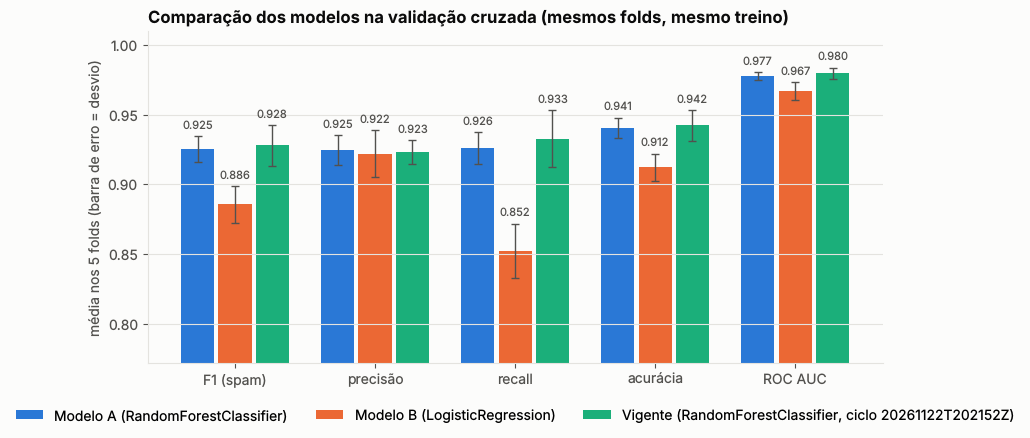

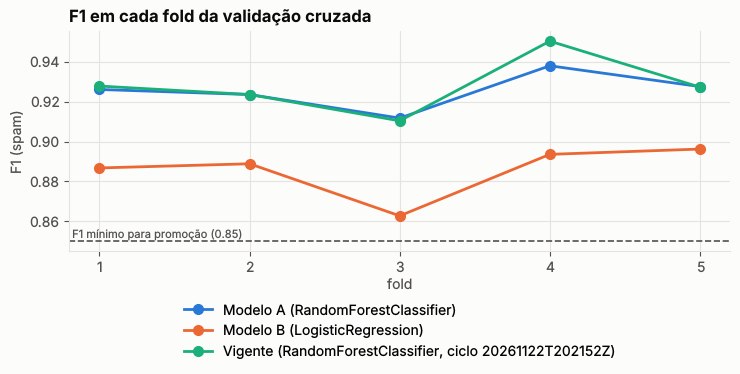

In [9]:
tabela_graf = pd.DataFrame({**RESUMOS, **({"vigente": RESUMO_VIGENTE} if RESUMO_VIGENTE else {})}).T
fig = graficos.grafico_comparacao_modelos(tabela_graf, METRICAS, ROTULOS)
graficos.salvar_figura(fig, cfg, CYCLE_ID, "03_comparacao_modelos")
fig = graficos.grafico_f1_por_fold({k: v[METRICA] for k, v in POR_FOLD.items()}, ROTULOS, cfg["promocao"]["f1_minimo"])
graficos.salvar_figura(fig, cfg, CYCLE_ID, "03_f1_por_fold")

## 10. Decisão de promoção

Regra (config.yaml, seção `promocao`):

* **Sem vigente:** promove o desafiante se F1 >= `f1_minimo` (0,85).
* **Com vigente:** promove se F1 >= 0,85 **e** F1 do desafiante - F1 do vigente reavaliado >= `limiar_melhoria` (0,005).
* Caso contrário, mantém o vigente.

O limiar de 0,005 existe porque trocar de modelo tem custo (risco, revalidação, comunicação). Uma diferença menor do que isso está dentro da variação natural entre folds e não justifica a troca. O F1 mínimo garante que nunca vai para produção um modelo ruim, mesmo que seja o melhor disponível.

In [10]:
cand = CANDIDATOS[VENCEDOR]
f1_vig = None if RESUMO_VIGENTE is None else RESUMO_VIGENTE[f"{METRICA}_media"]
DECISAO = P.decidir_promocao(RESUMOS[VENCEDOR][f"{METRICA}_media"], f1_vig, cfg)
DECISAO["vencedor"] = VENCEDOR
DECISAO["algoritmo_vencedor"] = cand["algoritmo"]

tabela_decisao = pd.DataFrame([{"cycle_id": CYCLE_ID, "data_version": DATA_VERSION, **DECISAO,
                                "run_id_desafiante": cand["run_id"],
                                "run_id_vigente_anterior": None if VIGENTE is None else VIGENTE["run_id"]}])
graficos.salvar_tabela(tabela_decisao, cfg, CYCLE_ID, "03_decisao")
print("DECISÃO:", DECISAO["decisao"].upper())
print(DECISAO["motivo"])
tabela_decisao.T

DECISÃO: MANTIDO_VIGENTE
Ganho de F1 -0.0025 sobre o vigente (0.9280) é menor que o limiar 0.005: vigente mantido.


,0
cycle_id,20261122T202252Z
data_version,lotes-01+02_h0ce6906487cc
promover,False
decisao,mantido_vigente
motivo,Ganho de F1 -0.0025 sobre o vigente (0.9280) é...
f1_desafiante,0.92548
f1_vigente_reavaliado,0.927968
ganho_f1,-0.002488
passa_f1_minimo,True
f1_minimo,0.85


## 11. Atualização do manifesto `models/modelo_vigente.json`

O manifesto é a fonte da verdade sobre qual modelo está em produção. O notebook 04 carrega o modelo a partir dele.

* **Se promovido:** passa a descrever o novo vigente (run_id, algoritmo, hiperparâmetros, cycle_id, data_version, features, métrica, arquivo do modelo, decisão e motivo).
* **Se mantido:** os dados do modelo continuam os do vigente anterior.
* Em ambos os casos, `ultima_decisao` registra a avaliação deste ciclo e `historico_decisoes` acumula todas as decisões.

In [11]:
novo = {
    "run_id": cand["run_id"],
    "nome_modelo": VENCEDOR,
    "algoritmo": cand["algoritmo"],
    "hiperparametros": cand["hiperparametros"],
    "seed": SEED,
    "data_version": DATA_VERSION,
    "features": ELEITAS,
    "metrica": {"nome": METRICA, "valor": RESUMOS[VENCEDOR][f"{METRICA}_media"],
                "desvio": RESUMOS[VENCEDOR][f"{METRICA}_desvio"],
                "todas": {k: v for k, v in RESUMOS[VENCEDOR].items() if k.endswith("_media")}},
    "arquivo_modelo": cand["arquivo_modelo"],
    "modelo_uri": cand["modelo_uri"],
    "modelo_hash": cand["hash"],
}
MANIFESTO = P.atualizar_manifesto(cfg, DECISAO, CYCLE_ID, novo)
{k: v for k, v in MANIFESTO.items() if k not in ("historico_decisoes", "features", "hiperparametros")}

{'run_id': 'a981929ec7cd49e5ba62fb05e46835e5',
 'nome_modelo': 'modelo_a',
 'algoritmo': 'RandomForestClassifier',
 'seed': 42,
 'data_version': 'lotes-01_h59fffbce7fcb',
 'metrica': {'nome': 'f1',
  'valor': 0.9262015060591275,
  'desvio': 0.002183105472696494,
  'todas': {'f1_media': 0.9262015060591275,
   'precision_media': 0.9282328575116306,
   'recall_media': 0.9243781094527364,
   'accuracy_media': 0.9412934150557912,
   'roc_auc_media': 0.9784094768471349}},
 'arquivo_modelo': 'models/historico/RandomForestClassifier_6cde58f70ec1b569.joblib',
 'modelo_uri': 'runs:/a981929ec7cd49e5ba62fb05e46835e5/modelo',
 'modelo_hash': '6cde58f70ec1b569',
 'cycle_id': '20261122T202152Z',
 'decisao': 'promovido',
 'motivo': 'Primeiro ciclo sem modelo vigente. F1 0.9262 >= mínimo 0.85: promovido.',
 'promovido_em': '2026-11-22T20:22:29+00:00',
 'ultima_decisao': {'cycle_id': '20261122T202252Z',
  'avaliado_em': '2026-11-22T20:23:34+00:00',
  'promover': False,
  'decisao': 'mantido_vigente',
  

## 12. Run de decisão no MLflow

Um run separado, com `etapa = decisao`, registra a regra, os números comparados e o resultado. Assim, na interface do MLflow, é possível ver para cada ciclo quem competiu, quem venceu e se houve promoção, sem abrir os notebooks.

In [12]:
with mlflow.start_run(run_name=f"decisao_{CYCLE_ID}") as run:
    mlflow.set_tags({"etapa": "decisao", "cycle_id": CYCLE_ID, "data_version": DATA_VERSION,
                     "decisao": DECISAO["decisao"], "motivo": DECISAO["motivo"], "vencedor": VENCEDOR,
                     "run_id_desafiante": cand["run_id"], "run_id_vigente_apos": str(MANIFESTO.get("run_id"))})
    mlflow.log_params({"cycle_id": CYCLE_ID, "data_version": DATA_VERSION, "metrica_principal": METRICA,
                       "f1_minimo": cfg["promocao"]["f1_minimo"], "limiar_melhoria": cfg["promocao"]["limiar_melhoria"],
                       "algoritmo_vencedor": cand["algoritmo"],
                       "run_id_vigente_anterior": None if VIGENTE is None else VIGENTE["run_id"]})
    mlflow.log_metrics({"f1_modelo_a": RESUMOS["modelo_a"][f"{METRICA}_media"],
                        "f1_modelo_b": RESUMOS["modelo_b"][f"{METRICA}_media"],
                        "f1_desafiante": DECISAO["f1_desafiante"],
                        **({"f1_vigente_reavaliado": f1_vig, "ganho_f1": DECISAO["ganho_f1"]} if f1_vig is not None else {}),
                        "promovido": int(DECISAO["promover"])})
    for arq in sorted(caminho(cfg["caminhos"]["figuras"]).glob(f"{CYCLE_ID}_03_*")):
        mlflow.log_artifact(str(arq), artifact_path="decisao")
    mlflow.log_dict({k: v for k, v in MANIFESTO.items() if k != "historico_decisoes"}, "modelo_vigente.json")
    RUN_ID_DECISAO = run.info.run_id

ingestao.atualizar_ciclo(cfg, etapas={**ingestao.carregar_ciclo(cfg)["etapas"], "03_competicao_promocao": "concluido"},
                         run_ids_modelos={k: v["run_id"] for k, v in CANDIDATOS.items()},
                         run_id_reavaliacao_vigente=RUN_ID_REAVALIACAO, run_id_decisao=RUN_ID_DECISAO,
                         vencedor=VENCEDOR, decisao=DECISAO)
print("Run de decisão:", RUN_ID_DECISAO)

Run de decisão: c2fd6f2cb791499b8c295c331aacfd63


## 13. Resumo

| Arquivo em `reports/figuras/` | Conteúdo |
|---|---|
| `<cycle_id>_03_metricas_por_fold.csv` | métricas de cada modelo em cada fold |
| `<cycle_id>_03_comparacao_a_x_b.csv` | média e desvio de cada métrica, A x B |
| `<cycle_id>_03_comparacao_modelos.png` | barras comparando A, B e o vigente reavaliado |
| `<cycle_id>_03_f1_por_fold.png` | F1 fold a fold |
| `<cycle_id>_03_decisao.csv` | decisão de promoção e motivo |

Próximo passo: **notebook 04**, previsões no teste fixo com o modelo vigente e explicabilidade com SHAP.

In [13]:
print(f"Ciclo {CYCLE_ID} | vencedor: {ROTULOS[VENCEDOR]} | decisão: {DECISAO['decisao']} | vigente: {MANIFESTO.get('algoritmo')} ({MANIFESTO.get('run_id')})")

Ciclo 20261122T202252Z | vencedor: Modelo A (RandomForestClassifier) | decisão: mantido_vigente | vigente: RandomForestClassifier (a981929ec7cd49e5ba62fb05e46835e5)
